# 06 — Which proteins are predicted well, and main figures

**Descriptive only.** This notebook reads the predictions saved in Phase 5. Nothing is refit, tuned or
remapped.

Two per-protein questions, answered with ridge 3a (deterministic; the MLP is shown for comparison):
* **(a)** How well is a protein predicted overall? Pearson over all random-split test cells.
* **(b)** How much transferable, cell-level signal is there? Within cell type x sample Pearson on unseen
  sites (the 4 site folds pooled).

Per-protein properties are related to performance across the 110 primary proteins. These associations
were looked at after the results were known (post hoc). They describe patterns; they do not establish
causes.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from citeseq.paths import CITE_H5AD, RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR, REPO_ROOT
from citeseq.io import load_cite, _read_dataframe
from citeseq.splits import load_split, group_folds
from citeseq.correlation import within_group_pearson, summarize_within, pearson_columns, load_protein_gene_map
from citeseq.metrics import evaluate
from citeseq.phase5 import group_bias
from citeseq import plotting as P

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
MIN_CELLS = 50
with h5py.File(CITE_H5AD) as f:
    var = _read_dataframe(f["var"])
adt = load_cite(CITE_H5AD, "X", var_mask=(var["feature_types"] == "ADT").to_numpy())
Y = adt.X.toarray().astype(np.float64)
obs = adt.obs
proteins = list(adt.var_names)
gex_names = var.index[var["feature_types"] == "GEX"]
pmap = load_protein_gene_map(REPO_ROOT / "resources/protein_gene_map.csv", gex_names).set_index("protein").loc[proteins]
prim = np.flatnonzero((pmap["analysis_set"] == "primary").to_numpy())
ct = obs["cell_type"].astype(str).to_numpy()
ts = np.char.add(np.char.add(ct.astype(str), " | "), obs["batch"].astype(str).to_numpy().astype(str))
split = load_split(RESULTS_DIR / "splits/random_split.csv.gz", obs.index)
load = lambda name: (lambda z: (z["preds"].item(), z["state"].item()))(np.load(PROCESSED_DIR / f"phase5/{name}.npz", allow_pickle=True))
print(Y.shape, len(prim), "primary proteins")

(90261, 134) 110 primary proteins


## 1. Per-protein performance

In [2]:
# (a) random-split test
te_R = np.flatnonzero((split == "test").to_numpy())
pR, _ = load("R_random")
perf = pd.DataFrame(index=pd.Index(proteins, name="protein"))
eR = evaluate(Y[te_R], pR["ridge 3a"], ct[te_R], proteins, MIN_CELLS)
perf["R_overall_ridge"] = eR["pearson_all"]
perf["R_within_type_ridge"] = eR["within_w"]
perf["R_overall_mlp"] = np.mean([evaluate(Y[te_R], pR[f"MLP s{s}"], ct[te_R], proteins, MIN_CELLS)["pearson_all"] for s in range(3)], axis=0)
perf["R_overall_celltype_mean"] = evaluate(Y[te_R], pR["cell-type mean"], ct[te_R], proteins, MIN_CELLS)["pearson_all"]

# (b) unseen sites: 4 site folds pooled
long_r = {"ridge 3a": [], "MLP s0": []}
num, den, overall_c = np.zeros(len(proteins)), np.zeros(len(proteins)), {"ridge 3a": [], "MLP s0": [], "cell-type mean": []}
for site, test in group_folds(obs, "Site").items():
    te = np.flatnonzero(test)
    p, st = load(f"C_{site}")
    seen = np.isin(ct[te], st["train_types"])
    for m in long_r:
        lr = within_group_pearson(p[m], Y[te], ts[te], MIN_CELLS)
        long_r[m].append(lr.assign(group=site + "/" + lr["group"]))
    for m in overall_c:
        overall_c[m].append(pearson_columns(p[m], Y[te]))
    lb_m = group_bias(Y[te], p["ridge 3a"], ts[te], st["sd_train"], MIN_CELLS, keep=seen)
    lb_r = group_bias(Y[te], p["cell-type mean"], ts[te], st["sd_train"], MIN_CELLS, keep=seen)
    num += (lb_m["n"] * lb_m["b"].abs()).groupby(lb_m["j"]).sum().reindex(range(len(proteins)), fill_value=0).to_numpy()
    den += (lb_r["n"] * lb_r["b"].abs()).groupby(lb_r["j"]).sum().reindex(range(len(proteins)), fill_value=0).to_numpy()
for m, key in [("ridge 3a", "ridge"), ("MLP s0", "mlp")]:
    s = summarize_within(pd.concat(long_r[m], ignore_index=True), len(proteins))
    perf[f"C_within_type_sample_{key}"] = s["weighted_mean"].to_numpy()
    perf[f"C_overall_{key}"] = np.mean(overall_c[m], axis=0)
perf["C_overall_celltype_mean"] = np.mean(overall_c["cell-type mean"], axis=0)
perf["C_shift_captured_ridge"] = 1 - num / den
perf["analysis_set"] = pmap["analysis_set"]
perf["genes"] = pmap["genes"]
P_ = perf.iloc[prim]
print("ridge vs MLP rank agreement across the 110 primary proteins (Spearman):")
print("  (a) R overall:", round(spearmanr(P_["R_overall_ridge"], P_["R_overall_mlp"])[0], 3),
      "| (b) C within type x sample:", round(spearmanr(P_["C_within_type_sample_ridge"], P_["C_within_type_sample_mlp"], nan_policy="omit")[0], 3))

ridge vs MLP rank agreement across the 110 primary proteins (Spearman):
  (a) R overall: 0.991 | (b) C within type x sample: 0.984


## 2. Per-protein properties (all cells, descriptive)

* `eta2_cell_type`: share of the protein's CLR variance explained by cell-type means.
* `sample_share`: share of variance between samples within a cell type (type x sample means around type
  means). This measures how large the sample/site shifts are.
* `signal_vs_isotype`: median over cells of protein CLR minus mean isotype CLR.
* From Phase 2: own-gene correlation (overall, within type) and the share of cells with the own gene's
  RNA detected.

In [3]:
def var_shares(Yc, labels):
    df = pd.DataFrame(Yc)
    g = df.groupby(labels)
    means = g.transform("mean").to_numpy()
    return means

tot = ((Y - Y.mean(0)) ** 2).sum(0)
m_type = var_shares(Y, ct)
m_ts = var_shares(Y, ts)
perf["eta2_cell_type"] = 1 - ((Y - m_type) ** 2).sum(0) / tot
perf["sample_share"] = ((m_ts - m_type) ** 2).sum(0) / tot
iso = adt.obsm["ADT_isotype_controls"].to_numpy(dtype=np.float64).mean(1)
perf["signal_vs_isotype"] = np.median(Y - iso[:, None], axis=0)
p2 = pd.read_csv(RESULTS_DIR / "phase2_protein_rna_correlation.csv").set_index("protein")
for c_src, c_dst in [("pearson_all", "own_gene_r_all"), ("pearson_within_w", "own_gene_r_within"), ("rna_detected_frac", "own_rna_detected")]:
    perf[c_dst] = p2[c_src].reindex(perf.index)
P_ = perf.iloc[prim]
props = ["eta2_cell_type", "sample_share", "signal_vs_isotype", "own_gene_r_all", "own_gene_r_within", "own_rna_detected"]
outs = ["R_overall_ridge", "C_within_type_sample_ridge", "C_shift_captured_ridge"]
assoc = pd.DataFrame({o: [spearmanr(P_[o], P_[c], nan_policy="omit")[0] for c in props] for o in outs}, index=props)
print("Spearman correlation across 110 primary proteins (post hoc, descriptive):")
assoc

Spearman correlation across 110 primary proteins (post hoc, descriptive):


,R_overall_ridge,C_within_type_sample_ridge,C_shift_captured_ridge
eta2_cell_type,0.945,0.625,0.461
sample_share,-0.236,-0.165,0.062
signal_vs_isotype,-0.184,-0.033,0.070
own_gene_r_all,0.705,0.495,0.442
own_gene_r_within,0.647,0.746,0.588
own_rna_detected,0.339,0.391,0.265


## 3. Best and worst proteins

In [4]:
cols = ["genes", "R_overall_ridge", "R_overall_celltype_mean", "C_within_type_sample_ridge", "C_overall_ridge",
        "eta2_cell_type", "sample_share", "signal_vs_isotype", "own_gene_r_all", "own_rna_detected"]
print("(a) random test, overall Pearson (ridge): top 10")
display(P_.sort_values("R_overall_ridge", ascending=False)[cols].head(10))
print("(a) bottom 10")
display(P_.sort_values("R_overall_ridge")[cols].head(10))

(a) random test, overall Pearson (ridge): top 10


,genes,R_overall_ridge,R_overall_celltype_mean,C_within_type_sample_ridge,C_overall_ridge,eta2_cell_type,sample_share,signal_vs_isotype,own_gene_r_all,own_rna_detected
protein,,,,,,,,,,
CD71,TFRC,0.941,0.918,0.214,0.919,0.840,0.070,0.816,0.437,0.222
CD72,CD72,0.924,0.881,0.177,0.895,0.778,0.099,-0.059,0.596,0.062
CD5,CD5,0.920,0.881,0.155,0.890,0.779,0.127,0.230,0.348,0.048
CD36,CD36,0.920,0.876,0.211,0.916,0.768,0.122,0.220,0.547,0.257
CD2,CD2,0.916,0.854,0.186,0.876,0.731,0.166,0.146,0.653,0.267
CD11c,ITGAX,0.905,0.864,0.244,0.898,0.745,0.074,-0.099,0.434,0.111
CD3,CD3E,0.904,0.864,0.108,0.860,0.750,0.158,0.148,0.679,0.263
CD19,CD19,0.902,0.878,0.129,0.879,0.767,0.093,-0.040,0.464,0.036
CD7,CD7,0.901,0.830,0.202,0.871,0.698,0.174,-0.006,0.588,0.204


(a) bottom 10


,genes,R_overall_ridge,R_overall_celltype_mean,C_within_type_sample_ridge,C_overall_ridge,eta2_cell_type,sample_share,signal_vs_isotype,own_gene_r_all,own_rna_detected
protein,,,,,,,,,,
CD42b,GP1BA,0.266,0.188,0.009,0.111,0.038,0.122,-0.076,0.001,0.004
CD119,IFNGR1,0.352,0.216,0.060,0.213,0.049,0.177,0.543,0.093,0.186
CD134,TNFRSF4,0.360,0.276,0.017,0.248,0.080,0.169,0.259,0.050,0.031
CD163,CD163,0.414,0.225,0.023,0.160,0.056,0.266,0.470,-0.016,0.077
CD270,TNFRSF14,0.421,0.296,0.025,0.187,0.094,0.237,0.823,0.014,0.238
CD25,IL2RA,0.422,0.388,0.075,0.385,0.139,0.082,-0.090,0.214,0.014
CD103,ITGAE,0.427,0.542,0.044,0.379,0.278,0.109,-0.048,-0.021,0.176
CD49a,ITGA1,0.428,0.344,0.090,0.289,0.118,0.161,-0.071,0.124,0.007
CD223,LAG3,0.438,0.223,0.007,0.193,0.060,0.346,0.324,-0.021,0.022


In [5]:
print("(b) unseen sites, within cell type x sample (ridge): top 10")
display(P_.sort_values("C_within_type_sample_ridge", ascending=False)[cols].head(10))
print("(b) bottom 10")
P_.sort_values("C_within_type_sample_ridge")[cols].head(10)

(b) unseen sites, within cell type x sample (ridge): top 10


,genes,R_overall_ridge,R_overall_celltype_mean,C_within_type_sample_ridge,C_overall_ridge,eta2_cell_type,sample_share,signal_vs_isotype,own_gene_r_all,own_rna_detected
protein,,,,,,,,,,
CD38,CD38,0.816,0.681,0.338,0.764,0.466,0.234,0.766,0.452,0.092
CD54,ICAM1,0.748,0.592,0.315,0.707,0.346,0.202,0.340,0.138,0.033
HLA-DR,HLA-DRA,0.825,0.714,0.301,0.784,0.503,0.224,0.450,0.616,0.510
CD35,CR1,0.883,0.815,0.298,0.871,0.664,0.087,0.219,0.347,0.085
CD9,CD9,0.818,0.696,0.281,0.784,0.477,0.163,0.405,0.468,0.054
CD82,CD82,0.764,0.654,0.280,0.729,0.438,0.228,0.614,0.301,0.115
CD62L,SELL,0.625,0.511,0.245,0.523,0.259,0.209,0.025,0.302,0.362
KLRG1,KLRG1,0.824,0.747,0.245,0.797,0.557,0.133,0.000,0.600,0.109
CD11c,ITGAX,0.905,0.864,0.244,0.898,0.745,0.074,-0.099,0.434,0.111


(b) bottom 10


,genes,R_overall_ridge,R_overall_celltype_mean,C_within_type_sample_ridge,C_overall_ridge,eta2_cell_type,sample_share,signal_vs_isotype,own_gene_r_all,own_rna_detected
protein,,,,,,,,,,
CD137,TNFRSF9,0.500,0.327,0.006,0.301,0.117,0.353,0.489,0.028,0.008
CD83,CD83,0.501,0.335,0.006,0.291,0.122,0.329,1.134,-0.065,0.090
CD223,LAG3,0.438,0.223,0.007,0.193,0.060,0.346,0.324,-0.021,0.022
CD42b,GP1BA,0.266,0.188,0.009,0.111,0.038,0.122,-0.076,0.001,0.004
CD154,CD40LG,0.569,0.338,0.013,0.310,0.126,0.471,1.004,-0.025,0.046
CD23,FCER2,0.511,0.285,0.017,0.254,0.092,0.397,0.888,0.059,0.049
CD134,TNFRSF4,0.360,0.276,0.017,0.248,0.080,0.169,0.259,0.050,0.031
CD152,CTLA4,0.549,0.366,0.018,0.341,0.141,0.378,0.640,-0.017,0.012
CD124,IL4R,0.518,0.327,0.019,0.298,0.113,0.393,0.661,0.076,0.106


In [6]:
# Proteins that drop most from random split to unseen sites (overall Pearson), and gain over cell-type mean
P_ = P_.assign(drop_R_to_C=P_["R_overall_ridge"] - P_["C_overall_ridge"],
               gain_over_ctm_R=P_["R_overall_ridge"] - P_["R_overall_celltype_mean"],
               gain_over_ctm_C=P_["C_overall_ridge"] - P_["C_overall_celltype_mean"])
print("largest drop random -> unseen sites (overall, ridge):")
display(P_.sort_values("drop_R_to_C", ascending=False)[["genes", "R_overall_ridge", "C_overall_ridge", "drop_R_to_C", "sample_share", "eta2_cell_type"]].head(10))
print("ridge minus cell-type mean, overall Pearson: median on R", round(P_["gain_over_ctm_R"].median(), 3),
      "| on unseen sites", round(P_["gain_over_ctm_C"].median(), 3),
      "| proteins where ridge beats the cell-type mean on unseen sites:", int((P_["gain_over_ctm_C"] > 0).sum()), "of", len(P_))
perf.to_csv(RESULTS_DIR / "phase6_per_protein.csv")

largest drop random -> unseen sites (overall, ridge):


,genes,R_overall_ridge,C_overall_ridge,drop_R_to_C,sample_share,eta2_cell_type
protein,,,,,,
CD47,CD47,0.756,0.192,0.564,0.644,0.180
HLA-E,HLA-E,0.446,0.155,0.290,0.262,0.092
CD154,CD40LG,0.569,0.310,0.259,0.471,0.126
CD23,FCER2,0.511,0.254,0.257,0.397,0.092
CD163,CD163,0.414,0.160,0.254,0.266,0.056
HLA-A-B-C,HLA-A;HLA-B;HLA-C,0.786,0.535,0.251,0.497,0.313
CD223,LAG3,0.438,0.193,0.245,0.346,0.060
CD270,TNFRSF14,0.421,0.187,0.234,0.237,0.094
IgM,IGHM,0.729,0.495,0.234,0.360,0.319


ridge minus cell-type mean, overall Pearson: median on R 0.084 | on unseen sites -0.0 | proteins where ridge beats the cell-type mean on unseen sites: 54 of 110


## 4. Main figures

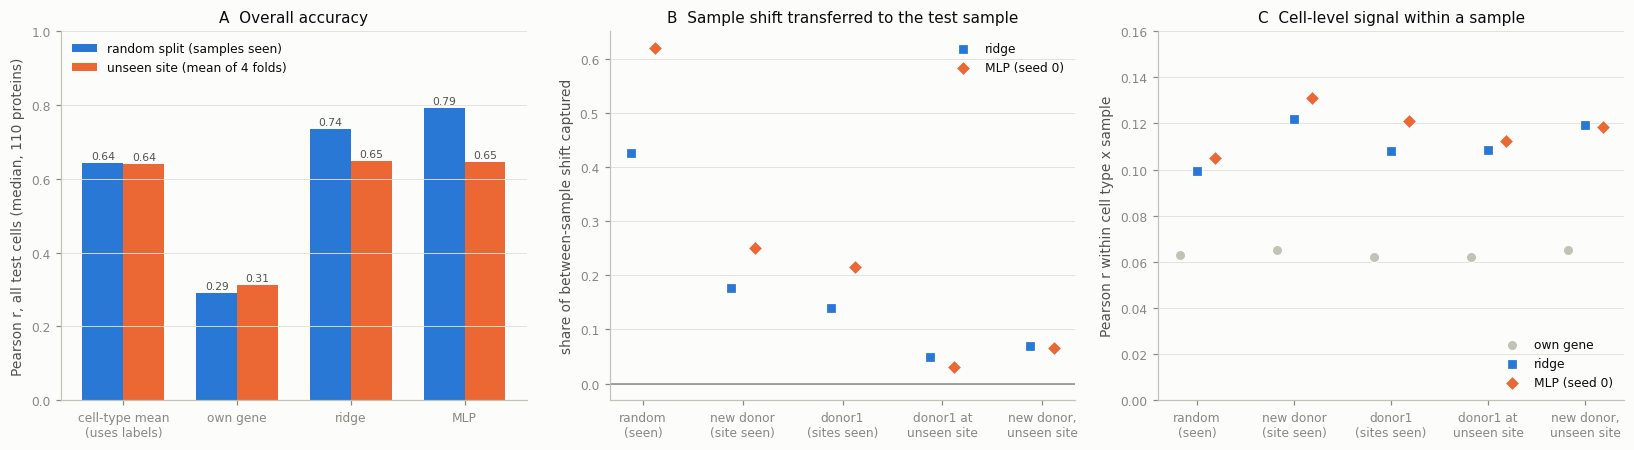

In [7]:
# Main figure 2: generalization across splits
rep = pd.read_csv(RESULTS_DIR / "phase5_report_groups.csv")
m3 = pd.read_csv(RESULTS_DIR / "phase5_m3_site_folds.csv")
pf = pd.read_csv(RESULTS_DIR / "phase5_per_fold.csv")
R_all = pf[(pf["split"] == "R")].set_index("model")["pearson all cells"]
R_all["MLP"] = R_all[["MLP s0", "MLP s1", "MLP s2"]].mean()
C_all = m3.groupby("model")["pearson all cells"].mean()
C_all["MLP"] = C_all["MLP s0"]
models = ["cell-type mean", "own gene", "ridge 3a", "MLP"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(models)); w = 0.36
ax = axes[0]
ax.bar(x - w / 2, [R_all[m] for m in models], w, color=P.BLUE, label="random split (samples seen)")
ax.bar(x + w / 2, [C_all[m] for m in models], w, color=P.ORANGE, label="unseen site (mean of 4 folds)")
for xi, (a, b) in enumerate(zip([R_all[m] for m in models], [C_all[m] for m in models])):
    ax.text(xi - w / 2, a + 0.01, f"{a:.2f}", ha="center", fontsize=7, color=P.INK_2)
    ax.text(xi + w / 2, b + 0.01, f"{b:.2f}", ha="center", fontsize=7, color=P.INK_2)
ax.set_xticks(x, ["cell-type mean\n(uses labels)", "own gene", "ridge", "MLP"])
ax.set_ylabel("Pearson r, all test cells (median, 110 proteins)"); ax.set_title("A  Overall accuracy")
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)

groups = ["R test", "D donors 2-9", "D donor1", "C donor1 cells", "C other donors"]
labels = ["random\n(seen)", "new donor\n(site seen)", "donor1\n(sites seen)", "donor1 at\nunseen site", "new donor,\nunseen site"]
def val(g, m, col):
    r = rep[(rep["report group"] == g) & (rep["model"] == m)]
    return r[col].iloc[0] if len(r) else np.nan
ax = axes[1]
xg = np.arange(len(groups))
for m, colr, mk, off, lab in [("ridge 3a", P.BLUE, "s", -0.12, "ridge"), ("MLP s0", P.ORANGE, "D", 0.12, "MLP (seed 0)")]:
    ax.scatter(xg + off, [val(g, m, "M2 shift captured") for g in groups], color=colr, marker=mk, s=45, label=lab,
               edgecolors=P.SURFACE, linewidths=0.8, zorder=3)
ax.axhline(0, color=P.MUTED, lw=1)
ax.set_xticks(xg, labels, fontsize=8); ax.set_ylabel("share of between-sample shift captured")
ax.set_title("B  Sample shift transferred to the test sample"); ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False)
ax = axes[2]
for m, colr, mk, off, lab in [("own gene", P.CONTEXT, "o", -0.18, "own gene"), ("ridge 3a", P.BLUE, "s", 0, "ridge"), ("MLP s0", P.ORANGE, "D", 0.18, "MLP (seed 0)")]:
    ax.scatter(xg + off, [val(g, m, "M1 within type x sample") for g in groups], color=colr, marker=mk, s=45, label=lab,
               edgecolors=P.SURFACE, linewidths=0.8, zorder=3)
ax.set_ylim(0, 0.16)
ax.set_xticks(xg, labels, fontsize=8); ax.set_ylabel("Pearson r within cell type x sample")
ax.set_title("C  Cell-level signal within a sample"); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "main_fig2_generalization.png")

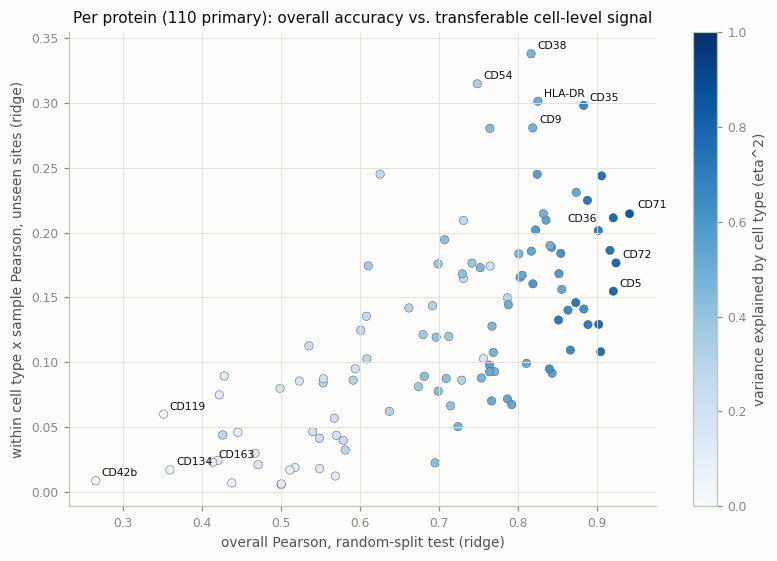

In [8]:
# Main figure 3: per protein, overall accuracy vs transferable cell-level signal
P_ = perf.iloc[prim]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sc_ = ax.scatter(P_["R_overall_ridge"], P_["C_within_type_sample_ridge"], c=P_["eta2_cell_type"], cmap="Blues",
                 vmin=0, vmax=1, s=30, edgecolors=P.INK_2, linewidths=0.3)
cb = fig.colorbar(sc_, ax=ax); cb.set_label("variance explained by cell type (eta^2)")
lab = pd.concat([P_.nlargest(5, "C_within_type_sample_ridge"), P_.nsmallest(4, "R_overall_ridge"), P_.nlargest(4, "R_overall_ridge")])
offsets = {"CD36": (-30, -3), "CD71": (5, 4)}
for name, row in lab[~lab.index.duplicated()].iterrows():
    ax.annotate(name, (row["R_overall_ridge"], row["C_within_type_sample_ridge"]), fontsize=7, color=P.INK,
                xytext=offsets.get(name, (4, 3)), textcoords="offset points")
ax.set_xlabel("overall Pearson, random-split test (ridge)")
ax.set_ylabel("within cell type x sample Pearson, unseen sites (ridge)")
ax.set_title("Per protein (110 primary): overall accuracy vs. transferable cell-level signal")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "main_fig3_proteins.png")